# 18. Evaluación de los modelos de regresión

Tarea principal del proyecto: número de sismos M ≥ 2,5 por celda el mes siguiente, con **RMSLE** como
métrica principal (cap. 1 y 3). Este capítulo responde a la sección 5.2 del enunciado: RMSE y MAE (además del
RMSLE) en la prueba, gráfico de entrenamiento, validación y prueba, y análisis de residuos (White, BDS, ACF con
Ljung-Box e histograma).

Se evalúan las **28 combinaciones benchmark** y el **modelo propuesto A+B v2** (cap. 22) en la **evaluación
definitiva en origen móvil** (cap. 13.11): cada año de 2021 a 2026 los modelos se reentrenan con todo el pasado
y pronostican ese año (69 meses, 11 754 filas). El campeón de cada modelo se elige con la validación interna
anterior a 2016, nunca con los meses evaluados.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Predicciones de regresión en el origen móvil 2021–2026
import json
from statsmodels.graphics.tsaplots import plot_acf
from src import benchmark as bm, resultados_e2 as r2
ev_, X, info, tr, gp, te = datos.panel_completo()
y = info["y"].astype(float); tm = info["tm"]
O = r2.origen_movil()
yo, tmo = O["y"], O["tm"]
CAMP = r2.campeones_om("reg")
REG = {r["etiqueta"]: r for r in r2.cargar("reg")}
AB2 = r2.ab2_prueba()
print(CAMP[["modelo", "variante", "validación < 2016"]].to_string(index=False))

           modelo        variante  validación < 2016
    Random Forest Genético (DEAP)           0.385922
          XGBoost Bayesiano (TPE)           0.386592
              KNN Bayesiano (TPE)           0.393956
              SVR Genético (DEAP)           0.394779
Árbol de decisión Bayesiano (TPE)           0.397050
            Ridge            Grid           0.401213
            Lasso            Grid           0.401214


## 18.1 Métricas y pruebas de supuestos en el origen móvil 2021–2026

Los residuos se calculan en la **escala de la métrica principal**, `log1p(y) − log1p(ŷ)`: es la escala en la
que se entrenó cada modelo (objetivo transformado, cap. 10) y en la que se mide el RMSLE.

- **White** (H0: varianza constante de los residuos frente a los valores ajustados y su cuadrado).
- **BDS** (H0: residuos independientes e idénticamente distribuidos; detecta dependencia no lineal), sobre una
  submuestra de 3 000 filas en orden temporal.

In [3]:
# RMSLE, RMSE y MAE de las 28 combinaciones y de A+B v2
filas = []
pred = {k: v for k, v in O.items() if " · " in k}
pred["A+B v2 (propuesto)"] = O["A+B v2"]
for nombre, p in pred.items():
    p = np.clip(p, 0, None)
    res = np.log1p(yo) - np.log1p(p)
    pr = ev.pruebas_residuos(res, np.log1p(p))
    filas.append({"modelo": nombre, "RMSLE": ev.rmsle(yo, p), "RMSE": float(np.sqrt(np.mean((p - yo) ** 2))),
                  "MAE": float(np.mean(np.abs(p - yo))), "p (White)": pr["White_p"], "p (BDS)": pr["BDS_p"],
                  "p (Jarque-Bera)": pr["JB_p"]})
TR = pd.DataFrame(filas).sort_values("RMSLE")
eda.guardar_tabla(TR, "e2_reg_prueba.csv")
TR.round(4)

,modelo,RMSLE,RMSE,MAE,p (White),p (BDS),p (Jarque-Bera)
28,A+B v2 (propuesto),0.3260,7.0489,0.5331,0.0,0.0,0.0
23,XGBoost · AG,0.3263,6.9571,0.5042,0.0,0.0,0.0
22,XGBoost · TPE,0.3270,6.9647,0.5086,0.0,0.0,0.0
21,XGBoost · Random,0.3272,6.9583,0.5061,0.0,0.0,0.0
18,Random Forest · TPE,0.3279,6.9442,0.4981,0.0,0.0,0.0
19,Random Forest · AG,0.3279,6.9442,0.4982,0.0,0.0,0.0
20,XGBoost · Grid,0.3285,6.9931,0.5193,0.0,0.0,0.0
17,Random Forest · Random,0.3291,6.9700,0.5119,0.0,0.0,0.0
12,Árbol de decisión · Grid,0.3297,6.9232,0.4938,0.0,0.0,0.0
14,Árbol de decisión · TPE,0.3308,6.9409,0.5017,0.0,0.0,0.0


In [4]:
# Lectura de las métricas de regresión
b = TR[TR.modelo != "A+B v2 (propuesto)"].iloc[0]
ab = TR[TR.modelo == "A+B v2 (propuesto)"].iloc[0]
pos_rmse = int(TR.RMSE.rank().loc[TR.modelo == 'A+B v2 (propuesto)'].iloc[0]); pos_mae = int(TR.MAE.rank().loc[TR.modelo == 'A+B v2 (propuesto)'].iloc[0])
md(f"- **A+B v2** tiene el menor RMSLE ({ab.RMSLE:.4f}). Entre las 28 combinaciones encabezan XGBoost y Random Forest; la comparación "
   f"formal del modelo propuesto se hace contra el campeón de cada familia (cap. 22.4). En RMSE y MAE, A+B v2 "
   f"queda en las posiciones {pos_rmse} y {pos_mae} de {len(TR)}"
   + (" (también es el mejor en esas dos métricas). " if pos_rmse == 1 and pos_mae == 1 else ". ") +
   f"El RMSE lo dominan unos pocos meses con "
   f"enjambres (decenas de sismos en una celda), así que premia a quien acierta esos picos; el RMSLE, que es la métrica elegida en "
   f"el Entregable 1, pesa por igual los errores relativos en celdas tranquilas y activas.\n"
   f"- **White** rechaza homocedasticidad en {int((TR['p (White)'] < 0.05).sum())} de {len(TR)} modelos y **BDS** rechaza "
   f"independencia en {int((TR['p (BDS)'] < 0.05).sum())} de {len(TR)}. Es lo esperado en conteos sísmicos: la varianza crece con "
   f"el nivel de actividad (sobredispersión) y los enjambres crean dependencia que ningún modelo con información solo hasta el mes "
   f"t puede anticipar del todo. No invalida las métricas de pronóstico, pero sí justifica que las pruebas de comparación (cap. 21) "
   f"usen errores estándar robustos (Newey-West) y bootstrap por bloques en lugar de supuestos i.i.d.")

- **A+B v2** tiene el menor RMSLE (0.3260). Entre las 28 combinaciones encabezan XGBoost y Random Forest; la comparación formal del modelo propuesto se hace contra el campeón de cada familia (cap. 22.4). En RMSE y MAE, A+B v2 queda en las posiciones 21 y 18 de 29. El RMSE lo dominan unos pocos meses con enjambres (decenas de sismos en una celda), así que premia a quien acierta esos picos; el RMSLE, que es la métrica elegida en el Entregable 1, pesa por igual los errores relativos en celdas tranquilas y activas.
- **White** rechaza homocedasticidad en 29 de 29 modelos y **BDS** rechaza independencia en 29 de 29. Es lo esperado en conteos sísmicos: la varianza crece con el nivel de actividad (sobredispersión) y los enjambres crean dependencia que ningún modelo con información solo hasta el mes t puede anticipar del todo. No invalida las métricas de pronóstico, pero sí justifica que las pruebas de comparación (cap. 21) usen errores estándar robustos (Newey-West) y bootstrap por bloques en lugar de supuestos i.i.d.

## 18.2 Entrenamiento, validación y prueba en un solo gráfico

Para que se vea el ajuste en cada subconjunto, se agrega por mes el **número total de sismos** (suma de las
celdas activas) y se compara con la suma de las predicciones del campeón de XGBoost y de A+B v2:

- **Entrenamiento** (2005–2020): predicción dentro de la muestra del modelo con que arranca el origen móvil
  (entrenado con todo lo anterior a 2021).
- **Validación** (dic-2017 a nov-2020): predicciones fuera de pliegue del **bucle externo** de la validación
  anidada (cap. 14), cada bloque anual predicho por un modelo que no lo vio. Para A+B v2, el 20 % final del
  entrenamiento con el combinador ajustado en el 80 % inicial (cap. 22), porque así se validó.
- **Prueba** (2021-01 a 2026-09): origen móvil.

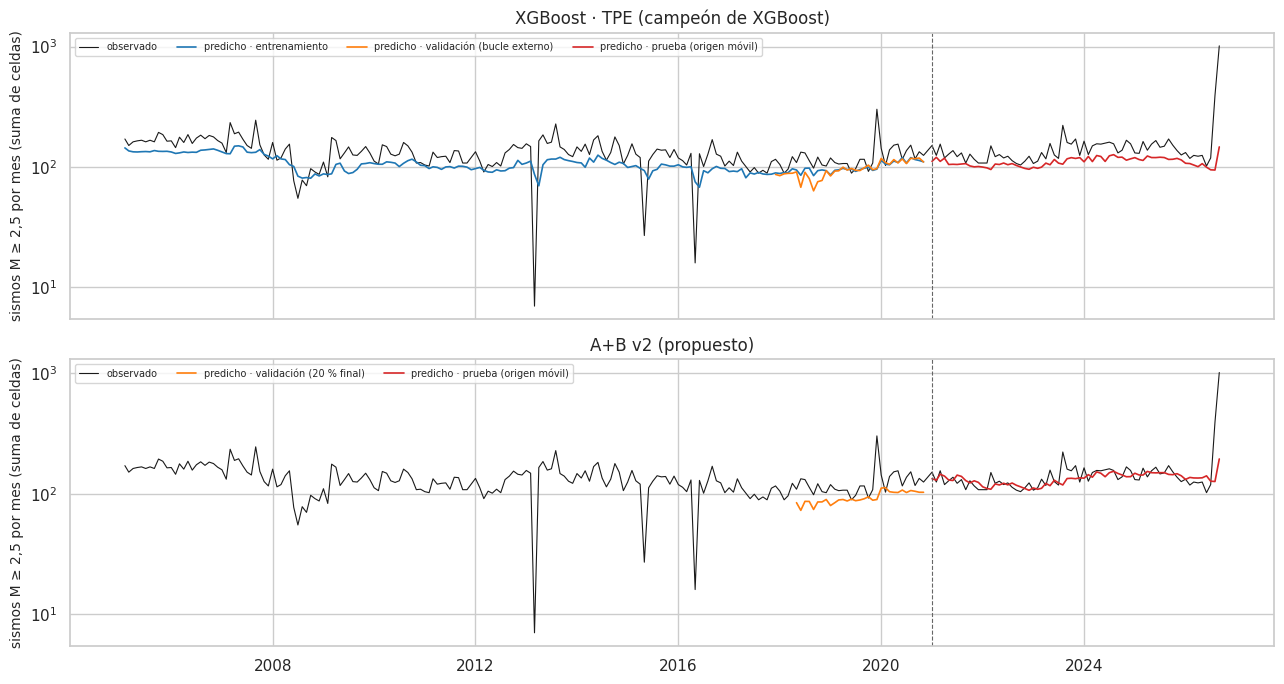

- **RMSLE del campeón de XGBoost por subconjunto:** entrenamiento 0.3464, validación 0.3189, prueba 0.3270. La validación (2018-2020) da **menos** error que el propio entrenamiento: esos años fueron más regulares que 2005-2017, que incluye meses con caídas abruptas del número de registros (los tres mínimos del gráfico, con 7, 16, 27 sismos en todo el país) que ningún modelo puede anticipar. No hay señal de sobreajuste: el error dentro de la muestra no es menor que fuera de ella.
- **Nivel.** La suma de predicciones queda sistemáticamente **por debajo** del total observado. No es un sesgo celda a celda (el residuo medio en escala log1p es ≈ 0, ver 18.3) sino el **sesgo de retransformación**: los modelos estiman el promedio de log(1 + y) y exp(·) − 1 de ese promedio es menor que el promedio de y cuando la distribución es asimétrica (desigualdad de Jensen). Es el precio de optimizar RMSLE: se acierta mejor la escala relativa celda a celda que el total.
- **Picos.** Ningún modelo anticipa los meses de enjambre (p. ej. el mes con más sismos del periodo evaluado, ≈ 1015, frente a 147 predichos por XGBoost y 194 por A+B v2): con información solo hasta el mes t se puede anticipar la persistencia de un enjambre, no su inicio.

In [5]:
# Curvas de entrenamiento, validación y prueba del campeón de XGBoost
cx = CAMP[CAMP.modelo == "XGBoost"].iloc[0]
par = json.load(open(r2.OM / "hp_bench" / f"{r2._slug('XGBoost', cx.variante)}.json"))["params"]
mx = bm.construir("reg", "XGBoost", par, X.columns, n_jobs=2).fit(X.iloc[tr], y[tr])
ent = mx.predict(X.iloc[tr])
rv = REG[cx.etiqueta]
fechas = pd.period_range("2004-01", periods=int(max(tm.max(), tmo.max())) + 1, freq="M").to_timestamp()

def serie(yy, tt, p):
    s_ = pd.DataFrame({"tm": tt, "y": yy, "p": np.clip(p, 0, None)}).groupby("tm").sum()
    s_.index = fechas[s_.index.values]
    return s_

s_tr = serie(y[tr], tm[tr], ent); s_va = serie(y[rv["oof_idx"]], tm[rv["oof_idx"]], rv["oof_pred"]); s_te = serie(yo, tmo, O[cx.etiqueta])
s_va_ab = serie(y[AB2["idx_val"]], tm[AB2["idx_val"]], AB2["oof_val"]); s_te_ab = serie(yo, tmo, O["A+B v2"])
fig, axs = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, (nom, partes) in zip(axs, ((f"{cx.etiqueta} (campeón de XGBoost)", (("entrenamiento", s_tr), ("validación (bucle externo)", s_va), ("prueba (origen móvil)", s_te))),
                                   ("A+B v2 (propuesto)", (("validación (20 % final)", s_va_ab), ("prueba (origen móvil)", s_te_ab))))):
    obs = pd.concat([s_tr.y, s_te.y]).sort_index()
    ax.plot(obs.index, obs.values, color="k", lw=0.8, label="observado")
    colores = ("#1f77b4", "#ff7f0e", "#d62728")[-len(partes):]
    for (lab, s_), c in zip(partes, colores):
        ax.plot(s_.index, s_.p.values, color=c, lw=1.2, label=f"predicho · {lab}")
    ax.axvline(fechas[info["m_test"]], color="0.4", ls="--", lw=0.8)
    ax.set_ylabel("sismos M ≥ 2,5 por mes (suma de celdas)"); ax.set_title(nom); ax.legend(fontsize=7, ncol=4)
    ax.set_yscale("log")
plt.tight_layout(); eda.guardar_figura(fig, "e2_reg_train_val_test.png"); plt.show()
r_tr = ev.rmsle(y[tr], ent); r_va = ev.rmsle(y[rv["oof_idx"]], rv["oof_pred"]); r_te = ev.rmsle(yo, O[cx.etiqueta])
md(f"- **RMSLE del campeón de XGBoost por subconjunto:** entrenamiento {r_tr:.4f}, validación {r_va:.4f}, prueba {r_te:.4f}. La "
   f"validación (2018-2020) da **menos** error que el propio entrenamiento: esos años fueron más regulares que 2005-2017, que incluye "
   f"meses con caídas abruptas del número de registros (los tres mínimos del gráfico, con "
   f"{', '.join(f'{v:.0f}' for v in s_tr.y.nsmallest(3).values)} sismos en todo el país) que ningún modelo puede anticipar. No hay señal "
   f"de sobreajuste: el error dentro de la muestra no es menor que fuera de ella.\n"
   f"- **Nivel.** La suma de predicciones queda sistemáticamente **por debajo** del total observado. No es un sesgo celda a celda (el "
   f"residuo medio en escala log1p es ≈ 0, ver 18.3) sino el **sesgo de retransformación**: los modelos estiman el promedio de log(1 + y) "
   f"y exp(·) − 1 de ese promedio es menor que el promedio de y cuando la distribución es asimétrica (desigualdad de Jensen). Es el "
   f"precio de optimizar RMSLE: se acierta mejor la escala relativa celda a celda que el total.\n"
   f"- **Picos.** Ningún modelo anticipa los meses de enjambre (p. ej. el mes con más sismos del periodo evaluado, ≈ {s_te.y.max():.0f}, "
   f"frente a {s_te.p.loc[s_te.y.idxmax()]:.0f} predichos por XGBoost y {s_te_ab.p.loc[s_te.y.idxmax()]:.0f} por A+B v2): con información "
   f"solo hasta el mes t se puede anticipar la persistencia de un enjambre, no su inicio.")

## 18.3 Residuos: autocorrelación, Ljung-Box e histograma

Para el campeón de cada modelo y A+B v2. La autocorrelación se calcula sobre la **serie mensual del
residuo medio** (69 meses), porque las filas de un mismo mes no son observaciones independientes en el tiempo.

In [6]:
# Residuos de los campeones: sesgo, forma y Ljung-Box sobre el residuo medio mensual
sel = {e: O[e] for e in CAMP.etiqueta}
sel["A+B v2 (propuesto)"] = O["A+B v2"]
filas, series = [], {}
for nombre, p in sel.items():
    res = np.log1p(yo) - np.log1p(np.clip(p, 0, None))
    sm = pd.Series(res).groupby(tmo).mean()
    series[nombre] = (res, sm)
    lb = ev.ljung_box(sm.values, lags=(1, 3, 6, 12))
    filas.append({"modelo": nombre, "media_residuo": res.mean(), "asimetría": stats.skew(res), "curtosis_exceso": stats.kurtosis(res),
                  **{f"LB p (rezago {int(r.rezago)})": r.lb_pvalue for _, r in lb.iterrows()}})
LB = pd.DataFrame(filas)
eda.guardar_tabla(LB, "e2_reg_residuos.csv")
LB.round(4)

,modelo,media_residuo,asimetría,curtosis_exceso,LB p (rezago 1),LB p (rezago 3),LB p (rezago 6),LB p (rezago 12)
0,Random Forest · AG,0.0005,2.8121,24.7466,0.4311,0.8132,0.6071,0.7552
1,XGBoost · TPE,-0.0012,2.7977,24.6773,0.5682,0.8865,0.6486,0.7862
2,KNN · TPE,0.0153,2.8375,23.9317,0.4718,0.8210,0.5700,0.7845
3,SVR · AG,-0.0712,2.9549,20.7550,0.5937,0.8209,0.4815,0.6516
4,Árbol de decisión · TPE,0.0015,2.7609,24.0675,0.3183,0.6783,0.6284,0.7914
5,Ridge · Grid,0.0013,2.3321,21.2278,0.3956,0.7587,0.6512,0.8878
6,Lasso · Grid,0.0012,2.3320,21.2262,0.3963,0.7593,0.6516,0.8882
7,A+B v2 (propuesto),0.0111,2.7472,24.5971,0.2838,0.5131,0.7684,0.5936


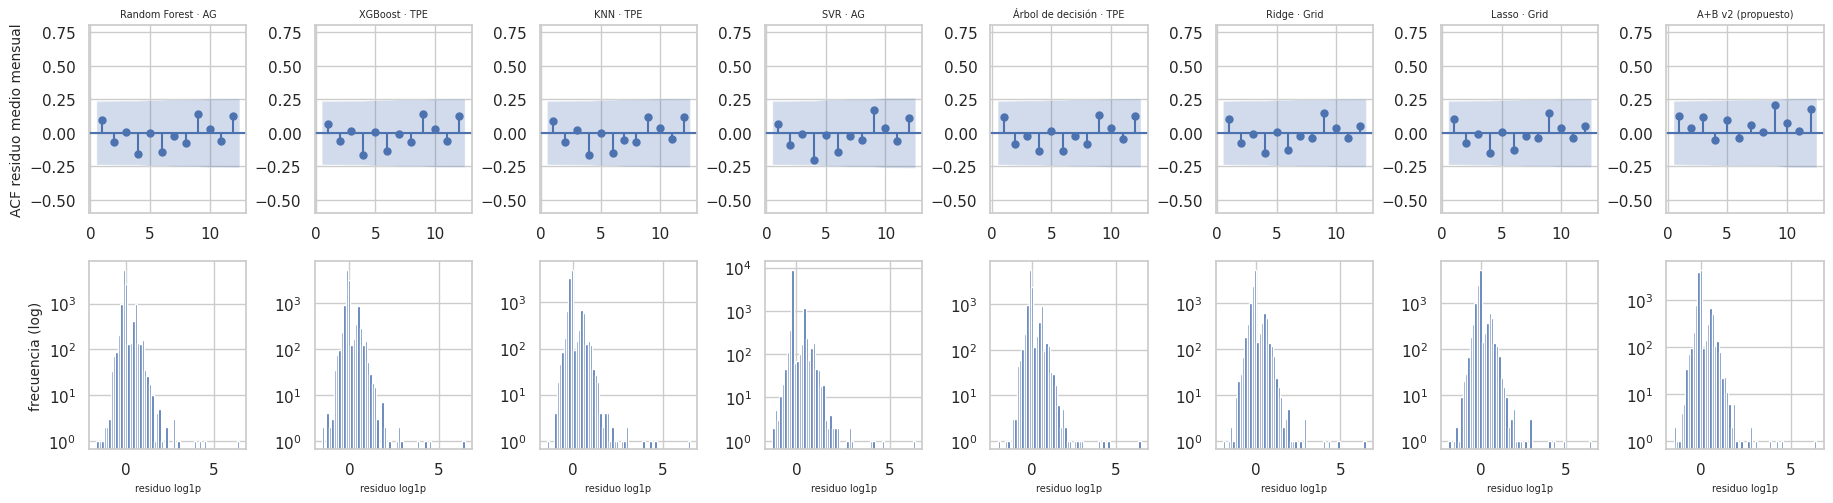

In [7]:
# ACF de los residuos mensuales e histogramas
fig, axs = plt.subplots(2, len(sel), figsize=(2.3 * len(sel), 5.2))
for j, (nombre, (res, sm)) in enumerate(series.items()):
    plot_acf(sm.values, lags=12, ax=axs[0, j], title="", zero=False)
    axs[0, j].set_title(nombre, fontsize=7); axs[0, j].set_ylim(-0.6, 0.8)
    axs[1, j].hist(res, bins=60, color="#4c72b0"); axs[1, j].set_yscale("log"); axs[1, j].set_xlabel("residuo log1p", fontsize=7)
axs[0, 0].set_ylabel("ACF residuo medio mensual"); axs[1, 0].set_ylabel("frecuencia (log)")
plt.tight_layout(); eda.guardar_figura(fig, "e2_reg_acf_hist.png"); plt.show()

In [8]:
# Lectura del diagnóstico de residuos
lb1 = LB.set_index("modelo")["LB p (rezago 1)"]; lb12 = LB.set_index("modelo")["LB p (rezago 12)"]
md(f"- **Sesgo.** El residuo medio en escala log1p está entre {LB.media_residuo.min():+.3f} y {LB.media_residuo.max():+.3f}: los "
   f"modelos son prácticamente **insesgados** en la escala en que se entrenaron.\n"
   f"- **Forma.** La distribución es muy asimétrica (asimetría ≈ {LB['asimetría'].median():.1f}) con cola derecha pesada (curtosis en "
   f"exceso ≈ {LB.curtosis_exceso.median():.0f}): la mayoría de las celdas-mes tienen 0 sismos y residuo cercano a 0, y unos pocos "
   f"enjambres dejan residuos grandes. Jarque-Bera rechaza normalidad en todos (18.1), lo que descarta pruebas que supongan errores "
   f"normales.\n"
   f"- **Dependencia serial.** Ljung-Box sobre el residuo medio mensual da p < 0,05 en el rezago 1 en {int((lb1 < 0.05).sum())} de "
   f"{len(lb1)} modelos y en el rezago 12 en {int((lb12 < 0.05).sum())} de {len(lb12)}: **no queda autocorrelación mensual** "
   f"significativa. Los modelos ya usan los rezagos (1, 3, 6 y 12 meses) y la estacionalidad, así que la dinámica temporal agregada "
   f"está capturada.\n"
   f"- **¿Por qué entonces BDS rechaza independencia (18.1)?** BDS trabaja fila a fila: detecta la dependencia **entre celdas de un "
   f"mismo mes** y la dependencia no lineal de los enjambres (una celda vecina activa cambia la distribución del residuo), que la "
   f"autocorrelación mensual no ve. Por eso el cap. 21 trata el **mes** como unidad (pérdidas mensuales, bootstrap por bloques de "
   f"meses) y usa varianza de Newey-West como protección adicional.")

- **Sesgo.** El residuo medio en escala log1p está entre -0.071 y +0.015: los modelos son prácticamente **insesgados** en la escala en que se entrenaron.
- **Forma.** La distribución es muy asimétrica (asimetría ≈ 2.8) con cola derecha pesada (curtosis en exceso ≈ 24): la mayoría de las celdas-mes tienen 0 sismos y residuo cercano a 0, y unos pocos enjambres dejan residuos grandes. Jarque-Bera rechaza normalidad en todos (18.1), lo que descarta pruebas que supongan errores normales.
- **Dependencia serial.** Ljung-Box sobre el residuo medio mensual da p < 0,05 en el rezago 1 en 0 de 8 modelos y en el rezago 12 en 0 de 8: **no queda autocorrelación mensual** significativa. Los modelos ya usan los rezagos (1, 3, 6 y 12 meses) y la estacionalidad, así que la dinámica temporal agregada está capturada.
- **¿Por qué entonces BDS rechaza independencia (18.1)?** BDS trabaja fila a fila: detecta la dependencia **entre celdas de un mismo mes** y la dependencia no lineal de los enjambres (una celda vecina activa cambia la distribución del residuo), que la autocorrelación mensual no ve. Por eso el cap. 21 trata el **mes** como unidad (pérdidas mensuales, bootstrap por bloques de meses) y usa varianza de Newey-West como protección adicional.

## 18.4 Conclusiones del capítulo

- En el origen móvil 2021–2026, A+B v2 tiene el menor RMSLE; entre los benchmark, XGBoost y Random Forest son
  los mejores (18.1).
- Los residuos son insesgados y sin autocorrelación mensual, pero heterocedásticos, no normales y dependientes
  entre celdas del mismo mes. La consecuencia práctica es comparar modelos con pérdidas mensuales y pruebas
  robustas (cap. 21).
- Ningún modelo anticipa el inicio de un enjambre; eso requeriría información que no existe al cierre del
  mes t.